# GRF galore

In [1]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

Loaded aesthetics module


In [2]:
import gstools as gs

gstools_mdls = {'spherical': gs.covmodel.Spherical, 
                'exponential': gs.covmodel.Exponential,
                'gaussian': gs.covmodel.Gaussian,
                'cubic': gs.covmodel.Cubic,
                'stable': gs.covmodel.Stable,
                'matern': gs.covmodel.Matern,
               'hole': gs.covmodel.JBessel}

In [3]:
import joblib

sphere_mesh = joblib.load(projdir + '/data/fsLR-4k_sphere_grf.pkl')

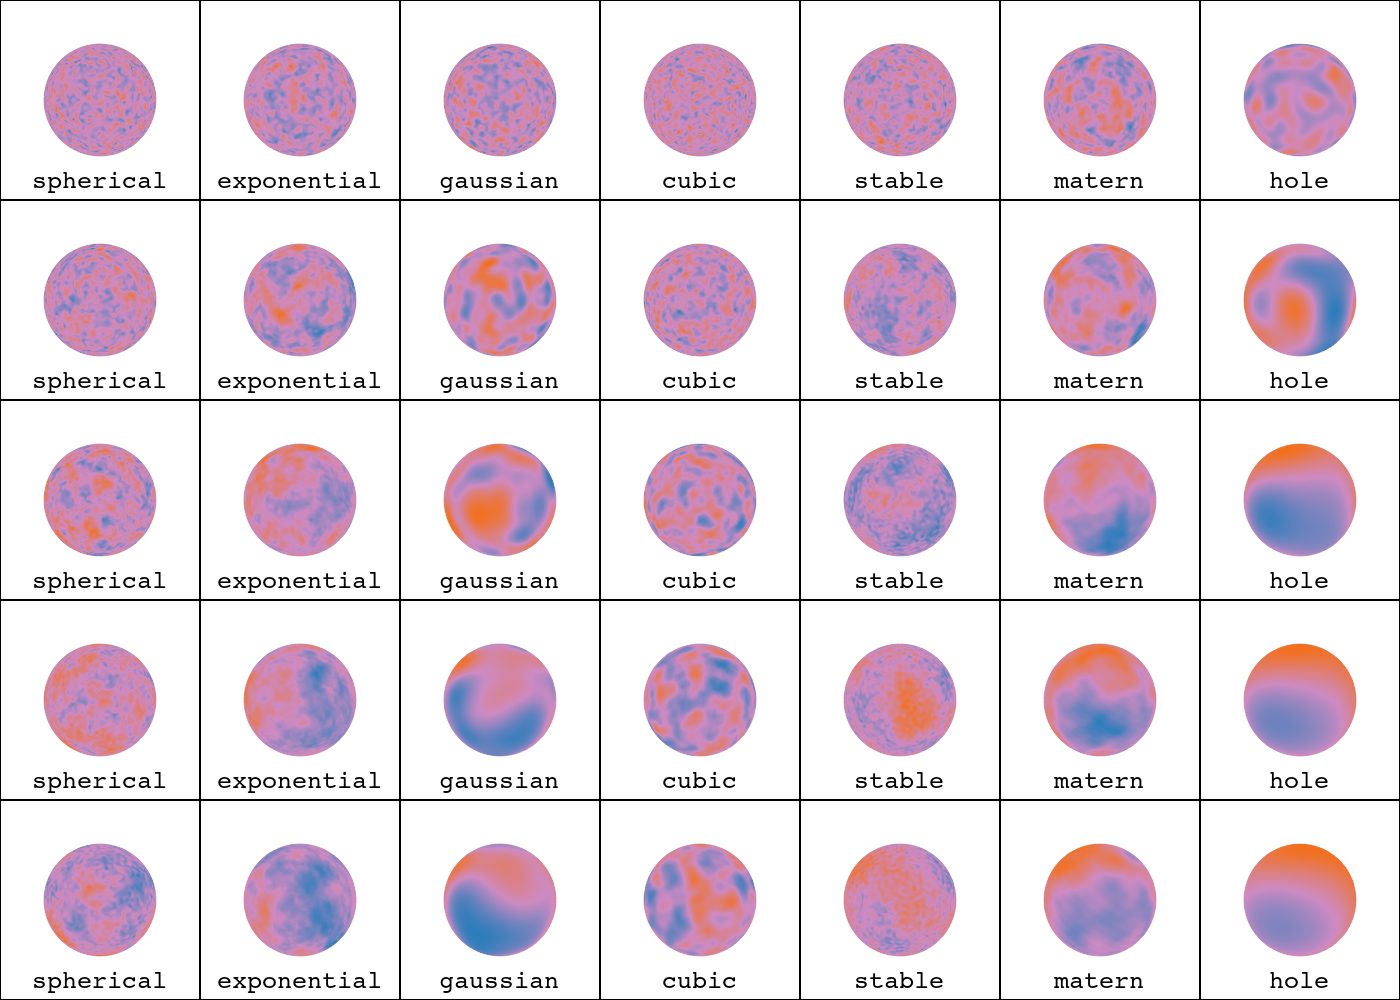

In [34]:
import copy
from interpmodules import helpers
import pyvista as pv


ranges=[10, 25, 50, 75, 100]

pl = pv.Plotter(shape = (len(ranges), len(gstools_mdls)), window_size = (len(gstools_mdls)*200, len(ranges)*200))

for ri,ran in enumerate(ranges):

    instances = {}
    
    for mi, model in enumerate(gstools_mdls):
        
        l = helpers._convert_to_length(ran)
        
        mdl = gstools_mdls[model](dim = 3, len_scale=l, var=1.0)
        srf = gs.SRF(mdl)
        random_map = srf.mesh(sphere_mesh, points='points', seed=321)
    
        instances[model] = random_map

        pl.subplot(ri,mi)
        tmp_mesh = copy.deepcopy(sphere_mesh)
        pl.add_mesh(tmp_mesh, scalars=instances[model], cmap = bpr, **mesh_aes)
        pl.add_text(model, position="lower_edge", font = 'courier', font_size=10)
        pl.camera_position='yz'

pl.show(jupyter_backend='static')

In [25]:
crosscorr = np.zeros((len(gstools_mdls), len(gstools_mdls)))

for mi, model1 in enumerate(gstools_mdls):
    for mj, model2 in enumerate(gstools_mdls):

        if mi == mj: continue
            
        crosscorr[mi, mj] = np.corrcoef(instances[model1], instances[model2])[1,0]

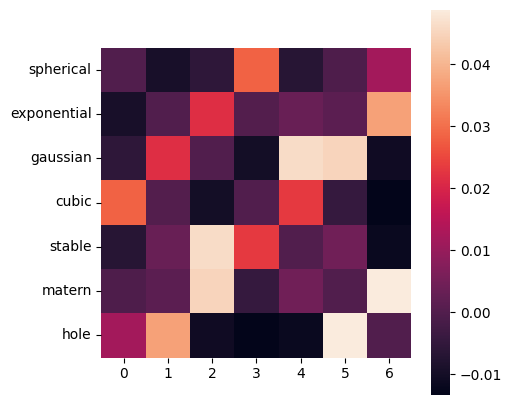

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(5,5))
sns.heatmap(crosscorr, square=True, yticklabels=gstools_mdls.keys())
plt.show()